# 02 · Pemodelan, Evaluasi & Threshold Bisnis
**Tujuan:** model yang menerima data paket saat dijemput → probabilitas terlambat + rekomendasi.
**Metrik utama:** PR-AUC (kelas positif ±18% → ROC-AUC/akurasi menyesatkan; PR-AUC fokus pada kualitas peringkat paket berisiko).

Alur: split waktu → baseline wajib → fitur rekayasa → model kompleks (LightGBM) → ablasi → ketidakpastian → kalibrasi → threshold biaya → test sekali → simpan artefak.

In [1]:
import sys, json, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score as ap, roc_auc_score, brier_score_loss
import lightgbm as lgb
from src.features import *
pd.set_option('display.width', 200)
raw = pd.read_csv('../data/raw.csv'); df = clean(raw)
tr, va, te = time_split(df)
y = lambda d: d.terlambat
pd.DataFrame({'n':[len(tr),len(va),len(te)], 'terlambat':[y(tr).mean(),y(va).mean(),y(te).mean()],
              'periode':[f'{s.tanggal_pickup.min().date()} → {s.tanggal_pickup.max().date()}' for s in (tr,va,te)]},
             index=['train','validation','test']).round(3)

,n,terlambat,periode
train,26633,0.178,2025-01-01 → 2025-12-31
validation,6623,0.219,2026-01-01 → 2026-03-31
test,6744,0.139,2026-04-01 → 2026-06-30


## 1. Split berdasarkan waktu (sesuai brief)
Pada produksi kita selalu memprediksi **masa depan**, jadi split acak akan membocorkan informasi musim. Pembagian: train Jan–Des 2025, validation Jan–Mar 2026, test Apr–Jun 2026.

**Peringatan penting:** tingkat terlambat validation (21,9%) jauh lebih tinggi daripada test (13,9%) karena **validation memuat lonjakan Maret** sedangkan **test hampir tanpa hari puncak** (0,2% paket). Konsekuensinya PR-AUC validation (≈0,66) dan test (≈0,38) **tidak sebanding**; selisihnya bukan overfitting, melainkan perbedaan campuran periode. PR-AUC juga otomatis lebih rendah ketika prevalensi lebih rendah (acuan acak = prevalensi). Kita laporkan keduanya dan juga validation tanpa hari puncak.

In [2]:
pk = va.volume_hub_hari >= 8000
print(f'validation: {pk.mean():.1%} paket di hari puncak (terlambat {y(va)[pk].mean():.1%}) vs hari biasa {y(va)[~pk].mean():.1%}')
print(f'test      : {(te.volume_hub_hari>=8000).mean():.2%} paket di hari puncak')
def evaluate(name, p, store=None):
    pv, pt = p.predict_proba(va)[:,1], p.predict_proba(te)[:,1]
    r = dict(model=name, val_PR=ap(y(va),pv), val_PR_biasa=ap(y(va)[~pk],pv[~pk]), test_PR=ap(y(te),pt),
             test_ROC=roc_auc_score(y(te),pt), test_brier=brier_score_loss(y(te),pt))
    if store is not None: store.append(r)
    return pv, pt
R = []

validation: 14.1% paket di hari puncak (terlambat 68.7%) vs hari biasa 14.2%
test      : 0.19% paket di hari puncak


## 2. Baseline wajib: regresi logistik dengan fitur asli
Dua versi supaya dampak cleaning terukur:
- **(a) mentah**: dummies dari data apa adanya (tanpa cleaning), hanya imputasi median + scaling;
- **(b) baseline resmi**: fitur asli setelah `clean()` (jarak diisi median kota, cuaca "tidak_diketahui"), tanpa fitur turunan.

In [3]:
# (a) baseline "mentah": semua kolom apa adanya, dummies kategori kotor
t_raw = pd.to_datetime(raw.tanggal_pickup)
Xn = pd.get_dummies(raw.drop(columns=['id_resi','tanggal_pickup','terlambat']), dtype=float, dummy_na=True)
mtr, mva, mte = t_raw <= TRAIN_END, (t_raw >= VAL_START) & (t_raw <= VAL_END), t_raw >= TEST_START
med = Xn[mtr].median(); Xn = Xn.fillna(med)
sc = StandardScaler().fit(Xn[mtr]); lr_n = LogisticRegression(max_iter=3000).fit(sc.transform(Xn[mtr]), raw.terlambat[mtr])
pv_n = lr_n.predict_proba(sc.transform(Xn[mva]))[:,1]; pt_n = lr_n.predict_proba(sc.transform(Xn[mte]))[:,1]
R.append(dict(model='LR mentah (tanpa cleaning)', val_PR=ap(raw.terlambat[mva],pv_n), val_PR_biasa=np.nan, test_PR=ap(raw.terlambat[mte],pt_n),
              test_ROC=roc_auc_score(raw.terlambat[mte],pt_n), test_brier=brier_score_loss(raw.terlambat[mte],pt_n)))
# (b) baseline resmi
LR = lambda C=1.0: LogisticRegression(C=C, max_iter=3000)
base = build_pipeline(LR(), feature_set='raw', scale=True).fit(tr, y(tr)); _ = evaluate('LR fitur asli (BASELINE)', base, R)
pd.DataFrame(R).round(4)

,model,val_PR,val_PR_biasa,test_PR,test_ROC,test_brier
0,LR mentah (tanpa cleaning),0.6461,NaN,0.3570,0.7454,0.1057
1,LR fitur asli (BASELINE),0.6455,0.3639,0.3563,0.7454,0.1058


**Temuan yang perlu jujur dicatat:** baseline "mentah" dan baseline "bersih" hampir identik (val ≈0,646; test ≈0,357). Jadi cleaning **tidak mengangkat skor** pada model linear ini. Alasannya: varian kategori hanya ±2% baris, `berat_kg` hampir tidak berhubungan dengan keterlambatan (lihat tingkat terlambat per kuantil berat yang datar), dan missing `jarak`/`cuaca` kecil. Cleaning tetap wajib karena menjaga kebenaran data (mis. berat 28.000 kg) dan konsistensi aplikasi, tetapi **sumber peningkatan skor ada di fitur rekayasa**, bukan di cleaning.

## 3. Fitur rekayasa (hanya info yang ada saat pickup)
Dasar tiap fitur berasal dari EDA:
| Fitur | Alasan |
|---|---|
| `setelah_17` | tingkat terlambat melonjak dua kali lipat sejak jam 17 (cut-off sortir) |
| `volume_peak` = max(0, volume−7000)/1000, `volume_log` | efek volume berbentuk ambang/hinge; regresi logistik tak bisa menangkap ambang dari fitur linear |
| `slack_hari` = SLA − transit | semakin sedikit "napas" waktu, semakin besar risiko (slack −2 → 48% terlambat) |
| `km_per_hari` | kecepatan yang dijanjikan |
| `hujan_lebat`, `hujan_apapun`, `cod`, `senin` | efek kategorikal kuat dari EDA |
| `berat_log`, `berat_hilang` | stabilisasi skala & penanda imputasi |
| `bulan` | musim kalender (diuji di ablasi) |

In [4]:
eng = build_pipeline(LR(), feature_set='eng', scale=True).fit(tr, y(tr)); pv_e, pt_e = evaluate('LR + fitur rekayasa', eng, R)
pd.DataFrame(R).round(4)

,model,val_PR,val_PR_biasa,test_PR,test_ROC,test_brier
0,LR mentah (tanpa cleaning),0.6461,NaN,0.3570,0.7454,0.1057
1,LR fitur asli (BASELINE),0.6455,0.3639,0.3563,0.7454,0.1058
2,LR + fitur rekayasa,0.6602,0.3975,0.3801,0.7598,0.1034


## 4. Apakah model yang lebih rumit lebih baik? LightGBM
Pohon boosting menangkap interaksi dan non-linearitas otomatis. Kita uji beberapa kapasitas dan regularisasi **hanya berdasarkan validation**.

In [5]:
def G(nl, ne=300, lr=0.03): return lgb.LGBMClassifier(n_estimators=ne, learning_rate=lr, num_leaves=nl, min_child_samples=100,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=10, random_state=0, verbose=-1)
gb = {}
for nl in [4, 8, 15, 31]:
    gb[nl] = build_pipeline(G(nl)).fit(tr, y(tr)); evaluate(f'LightGBM leaves={nl} (fitur rekayasa)', gb[nl], R)
evaluate('LightGBM fitur asli', build_pipeline(G(8), feature_set='raw').fit(tr, y(tr)), R)
res = pd.DataFrame(R).round(4); res

,model,val_PR,val_PR_biasa,test_PR,test_ROC,test_brier
0,LR mentah (tanpa cleaning),0.6461,NaN,0.3570,0.7454,0.1057
1,LR fitur asli (BASELINE),0.6455,0.3639,0.3563,0.7454,0.1058
2,LR + fitur rekayasa,0.6602,0.3975,0.3801,0.7598,0.1034
3,LightGBM leaves=4 (fitur rekayasa),0.6605,0.3879,0.3745,0.7582,0.1039
4,LightGBM leaves=8 (fitur rekayasa),0.6574,0.3850,0.3738,0.7569,0.1040
5,LightGBM leaves=15 (fitur rekayasa),0.6553,0.3825,0.3728,0.7555,0.1040
6,LightGBM leaves=31 (fitur rekayasa),0.6508,0.3744,0.3699,0.7520,0.1044
7,LightGBM fitur asli,0.6569,0.3854,0.3784,0.7563,0.1039


**Temuan:** LightGBM **tidak mengalahkan** regresi logistik berfitur rekayasa (skor sama atau sedikit lebih rendah, dan makin turun saat kapasitas naik). Alasan teknisnya:
1. Struktur masalahnya **hampir aditif pada skala log-odds** (transit, SLA, jam ≥17, cuaca, COD, volume memberi efek yang menumpuk), cocok dengan model linear *bila fiturnya benar*.
2. Satu-satunya non-linearitas besar (ambang volume) sudah kita tangkap dengan fitur hinge. Setelah itu, hampir tidak ada interaksi sisa untuk dipelajari pohon.
3. Berat paket dan banyak variabel lain nyaris tanpa sinyal; kapasitas ekstra hanya menambah varians (noise), terlihat dari skor yang turun ketika `num_leaves` naik.

Brief secara eksplisit menyatakan temuan seperti ini **sah**. Lagi pula regresi logistik memberi bonus: probabilitas yang terkalibrasi (penting untuk threshold biaya) dan penjelasan per-fitur untuk staf.

## 5. Ablasi: seberapa bergantung model pada `volume_hub_hari` dan `bulan`?
**Risiko kebocoran:** `volume_hub_hari` didefinisikan sebagai paket masuk hub *pada hari itu*. Bila nilai itu hanya diketahui di akhir hari, ia tidak tersedia saat pickup. Karena fitur terkuat, kita ukur taruhannya.

In [6]:
A = []
for nm, kw in [('LR eng: lengkap', {}), ('LR eng: tanpa volume', dict(use_volume=False)), ('LR eng: tanpa bulan', dict(use_month=False)),
               ('LR eng: tanpa volume & bulan', dict(use_volume=False, use_month=False))]:
    evaluate(nm, build_pipeline(LR(), scale=True, **kw).fit(tr, y(tr)), A)
pd.DataFrame(A).round(4)

,model,val_PR,val_PR_biasa,test_PR,test_ROC,test_brier
0,LR eng: lengkap,0.6602,0.3975,0.3801,0.7598,0.1034
1,LR eng: tanpa volume,0.4257,0.3936,0.3778,0.7573,0.1052
2,LR eng: tanpa bulan,0.6603,0.3978,0.3797,0.7598,0.1034
3,LR eng: tanpa volume & bulan,0.4270,0.3936,0.3778,0.7572,0.1050


**Pembacaan:**
- **Tanpa `volume`**: PR-AUC validation anjlok (≈0,66 → ≈0,43) karena hari puncak tak lagi terdeteksi; di test (tanpa hari puncak) nyaris tidak berubah. Jadi volume = **detektor hari puncak**.
- **Tanpa `bulan`**: skor tak berubah → model **tidak** bergantung pada kalender, melainkan pada beban hub yang menyebabkannya. Ini lebih sehat untuk produksi (tak perlu menghafal tanggal).

**Keputusan:** `volume_hub_hari` dipertahankan karena brief mendaftarkannya sebagai data yang tersedia saat pickup. Di produksi ia harus berupa *estimasi/pembacaan beban hub saat ini* (mis. paket masuk sampai sekarang, atau perkiraan harian operasional). **Ini asumsi yang wajib dikonfirmasi ke klien** dan dicatat di README/metadata. Jika tidak tersedia, gunakan versi tanpa volume (lebih lemah di hari puncak).

## 6. Ketidakpastian: apakah selisih skor nyata?
Selisih 0,01–0,02 PR-AUC bisa saja noise. *Paired bootstrap* pada test: ambil ulang paket yang sama untuk kedua model dan lihat sebaran selisih.

In [7]:
rng = np.random.default_rng(0); yt = y(te).values
pt_b, pt_g = base.predict_proba(te)[:,1], gb[8].predict_proba(te)[:,1]
def boot(p1, p2, B=500):
    d = []
    for _ in range(B):
        i = rng.integers(0, len(yt), len(yt)); d.append(ap(yt[i], p1[i]) - ap(yt[i], p2[i]))
    return np.mean(d), np.percentile(d, 2.5), np.percentile(d, 97.5)
for nm, a, b_ in [('LR rekayasa − LR baseline', pt_e, pt_b), ('LightGBM − LR rekayasa', pt_g, pt_e)]:
    m, lo, hi = boot(a, b_); print(f'{nm:30s} selisih PR-AUC test = {m:+.4f}  CI95 [{lo:+.4f}, {hi:+.4f}]')

LR rekayasa − LR baseline      selisih PR-AUC test = +0.0236  CI95 [+0.0134, +0.0336]


LightGBM − LR rekayasa         selisih PR-AUC test = -0.0067  CI95 [-0.0139, +0.0008]


Fitur rekayasa memberi peningkatan kecil tetapi konsisten (CI di atas 0). LightGBM vs LR rekayasa: selisih mendekati nol/negatif → tidak ada alasan memilih model yang lebih kompleks. **Model terpilih: regresi logistik + fitur rekayasa.**

## 7. Kalibrasi
Threshold berbasis biaya mengandalkan angka probabilitas yang jujur (p=0,3 harus benar-benar ±30% terlambat). Periksa *reliability* pada validation dan test.

In [8]:
pv_e, pt_e = eng.predict_proba(va)[:,1], eng.predict_proba(te)[:,1]
bins = [0, .05, .1, .2, .4, 1.0]
def rel(p, yy): 
    g = pd.DataFrame({'p':p,'y':yy.values}).groupby(pd.cut(p, bins, include_lowest=True)).agg(n=('y','size'), prediksi=('p','mean'), aktual=('y','mean')); return g.round(3)
display(rel(pv_e, y(va)).add_prefix('val_').join(rel(pt_e, y(te)).add_prefix('test_')))

,val_n,val_prediksi,val_aktual,test_n,test_prediksi,test_aktual
"(-0.001, 0.05]",981,0.039,0.037,1247,0.038,0.036
"(0.05, 0.1]",1745,0.073,0.055,2109,0.073,0.065
"(0.1, 0.2]",1543,0.143,0.130,1827,0.142,0.131
"(0.2, 0.4]",1199,0.279,0.292,1166,0.278,0.262
"(0.4, 1.0]",1155,0.645,0.663,395,0.522,0.537


Prediksi ≈ aktual di semua rentang (selisih ≤ ±0,02 di semua bin) → **tidak perlu kalibrasi tambahan**. Ini keuntungan regresi logistik (fungsi loss-nya memang log-loss).

## 8. Threshold dari alasan bisnis
Biaya: paket terlambat tanpa kabar (FN) = Rp50.000; kabar keliru (FP) = Rp5.000. Mengabari paket dengan probabilitas *p* diharapkan menghemat jika
`p × 50.000 > (1 − p) × 5.000  ⇒  p > 5.000/55.000 = 0,0909`.
Ambang rendah (±9%) wajar: salah-diam 10× lebih mahal, jadi kita rela banyak "alarm palsu". Verifikasi empiris pada kurva biaya validation:

threshold teoritis: 0.0909 | optimum empiris validation: 0.1 | optimum test (hanya referensi): 0.11


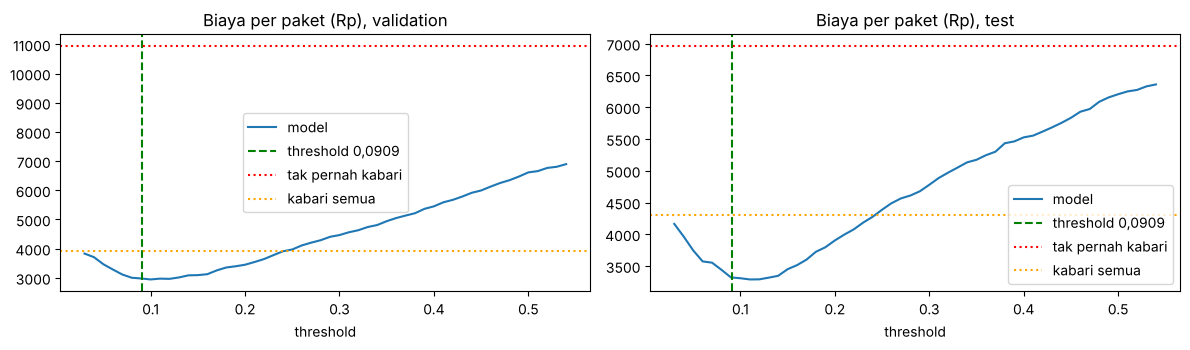

In [9]:
ths = np.round(np.arange(0.03, 0.55, 0.01), 2)
cv = [total_cost(y(va), pv_e, t)/len(va) for t in ths]; ct = [total_cost(y(te), pt_e, t)/len(te) for t in ths]
print('threshold teoritis:', round(5000/55000, 4), '| optimum empiris validation:', ths[int(np.argmin(cv))], '| optimum test (hanya referensi):', ths[int(np.argmin(ct))])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, c_, yy, ttl in [(ax[0], cv, y(va), 'validation'), (ax[1], ct, y(te), 'test')]:
    a.plot(ths, c_, label='model'); a.axvline(5000/55000, c='g', ls='--', label='threshold 0,0909')
    a.axhline(50000*yy.mean(), c='r', ls=':', label='tak pernah kabari'); a.axhline(5000*(1-yy.mean()), c='orange', ls=':', label='kabari semua')
    a.set_title(f'Biaya per paket (Rp), {ttl}'); a.set_xlabel('threshold'); a.legend()
plt.tight_layout()

Kurva biaya **datar di sekitar 0,09–0,12** dan titik teoritis berada di dasarnya → threshold **0,0909** dipakai (prinsipil, tidak di-*tune* pada test). Tier tambahan **p ≥ 0,40 = "Prioritaskan"**, yaitu paket yang >50% terlambat sehingga layak mendapat penanganan khusus (kapasitas prioritas terbatas).

## 9. Model final & evaluasi test (sekali)
`src.train.main()` mengulang alur ini: refit pada **train+validation** (supaya model melihat lonjakan Maret 2026, data terbaru) dengan hyperparameter yang sudah dipilih, evaluasi test **satu kali**, lalu menyimpan `models/model.joblib` dan `models/metadata.json`.

In [10]:
from src.train import main; main()
meta = json.load(open('../models/metadata.json'))
pd.DataFrame(meta['metrics']).T[['n','prevalence','pr_auc','roc_auc','precision@thr','recall@thr','cost_per_package_rp','cost_never_notify_rp','cost_always_notify_rp']]

{
  "validation_baseline_LR_fitur_asli": {
    "n": 6623,
    "prevalence": 0.2188,
    "pr_auc": 0.6455,
    "roc_auc": 0.8313,
    "brier": 0.1196,
    "precision@thr": 0.3229,
    "recall@thr": 0.9172,
    "cost_per_package_rp": 3010,
    "cost_never_notify_rp": 10939,
    "cost_always_notify_rp": 3906
  },
  "validation_kandidat_LR_fitur_rekayasa": {
    "n": 6623,
    "prevalence": 0.2188,
    "pr_auc": 0.6602,
    "roc_auc": 0.8403,
    "brier": 0.1166,
    "precision@thr": 0.323,
    "recall@thr": 0.9213,
    "cost_per_package_rp": 2973,
    "cost_never_notify_rp": 10939,
    "cost_always_notify_rp": 3906
  },
  "test_baseline_LR_fitur_asli": {
    "n": 6744,
    "prevalence": 0.1392,
    "pr_auc": 0.3549,
    "roc_auc": 0.7445,
    "brier": 0.1059,
    "precision@thr": 0.2069,
    "recall@thr": 0.8168,
    "cost_per_package_rp": 3456,
    "cost_never_notify_rp": 6962,
    "cost_always_notify_rp": 4304
  },
  "test_final_model": {
    "n": 6744,
    "prevalence": 0.1392,
    "pr

,n,prevalence,pr_auc,roc_auc,precision@thr,recall@thr,cost_per_package_rp,cost_never_notify_rp,cost_always_notify_rp
validation_baseline_LR_fitur_asli,6623.0,0.2188,0.6455,0.8313,0.3229,0.9172,3010.0,10939.0,3906.0
validation_kandidat_LR_fitur_rekayasa,6623.0,0.2188,0.6602,0.8403,0.3230,0.9213,2973.0,10939.0,3906.0
test_baseline_LR_fitur_asli,6744.0,0.1392,0.3549,0.7445,0.2069,0.8168,3456.0,6962.0,4304.0
test_final_model,6744.0,0.1392,0.3791,0.7592,0.2133,0.8243,3340.0,6962.0,4304.0


## 10. Kesimpulan
- **Baseline LR fitur asli** → test PR-AUC ≈ 0,355; **model final (LR + fitur rekayasa)** → ≈ 0,379 (acuan acak = 0,139). Peningkatan kecil tapi konsisten.
- **Model kompleks (LightGBM) tidak lebih baik** → temuan sah: struktur data aditif, non-linearitas utama sudah ditangkap fitur hinge, sisanya noise.
- **Nilai bisnis di test:** biaya ≈ Rp3.340/paket vs Rp6.962 (tak pernah mengabari) dan Rp4.304 (mengabari semua) → hemat ±52% dan ±22%.
- **Batasan jujur:** ROC-AUC test ≈ 0,76; di hari biasa, keterlambatan hanya sebagian terprediksi dari data pickup, dan model menangkap hari puncak dengan sangat baik (val ROC-AUC ≈ 0,84). Ketergantungan pada `volume_hub_hari` perlu dikonfirmasi ketersediaannya saat pickup; test tidak memuat hari puncak sehingga performa musim puncak hanya terbukti di validation; perlu pemantauan drift dan retraining berkala.